# Fractional Order Denoising for Large HDF5 Datasets

This notebook implements a scalable fractional order denoising pipeline for large HDF5 files.
It uses a **sliding window** approach to process data in chunks while maintaining continuity (memory) across boundaries, ensuring seamless denoising without artifacts.

## Key Features:
- **Chunked Processing**: Handles files larger than RAM.
- **Adaptive Optimization**: Runs Bayesian Optimization for **each chunk** to adapt to non-stationary signal/noise characteristics.
- **Sliding Window Memory**: Carries over fractional history between chunks.
- **Bayesian Optimization**: Automatically finds optimal $\beta$ and $\lambda$ parameters using the **Square-root rule** for histogram binning.
- **Interactive Visualization**: Allows inspecting specific ranges of the processed data.

## Environment setup
Install the dependencies listed in `requirements.txt` before running this notebook. Place your `.hdf5` input files in the repository's `data/` directory.


The notebook uses NumPy, pandas, SciPy, h5py, tqdm, Plotly, and bayesian-optimization. See the repository README for setup instructions.


In [ ]:
import numpy as np
import pandas as pd
import h5py
import math
from scipy import stats
import os
from tqdm import tqdm
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from bayes_opt import BayesianOptimization

# Ensure reproducible results
np.random.seed(42)

## 1. Core Denoising Functions

Here we define the mathematical core of the fractional denoising algorithm.

- `gl_weights`: Computes the Grünwald-Letnikov coefficients.
- `fractional_denoise_window`: The modified denoising function that accepts a `history` buffer. This allows us to resume denoising from the previous chunk's state.
- `renyi_contrast`: The objective function we want to maximize.

In [ ]:
def gl_weights(beta, N):
    """Compute Grünwald-Letnikov weights recursively."""
    c = np.zeros(N+1)
    c[0] = 1.0
    for k in range(1, N+1):
        c[k] = c[k-1] * (beta - (k-1)) / k
    w = np.array([((-1)**k) * c[k] for k in range(N+1)])
    return w

def fractional_denoise_window(y, beta, lam, history=None, memory=10000, dt=1.0):
    """
    Apply fractional denoising with a fixed memory window and history support.

    Args:
        y: Current chunk of noisy signal.
        beta: Fractional order.
        lam: Fidelity parameter.
        history: Previous cleaned values (numpy array) to maintain continuity.
        memory: Maximum memory length (truncation of the GL sum).
        dt: Time step.

    Returns:
        u: Cleaned chunk.
    """
    y = np.asarray(y, dtype=float)
    N = len(y)

    # 1. Prepare Weights
    w = gl_weights(beta, memory)
    C = dt**(-beta)
    den = lam + C * w[0]

    # 2. Prepare History
    if history is None:
        history = np.zeros(0)

    # Keep only the relevant recent history
    if len(history) > memory:
        history = history[-memory:]

    hist_len = len(history)

    # 3. Initialize Full Buffer (History + New Output)
    full_u = np.zeros(hist_len + N)
    full_u[:hist_len] = history

    # 4. Iterative Update
    for i in range(N):
        current_idx = hist_len + i

        # Determine how many past points to use (up to 'memory')
        limit = min(current_idx, memory)

        if limit > 0:
            # Extract segment: u[n-1] ... u[n-limit]
            segment = full_u[current_idx-limit : current_idx][::-1]
            S = np.dot(w[1:limit+1], segment)
        else:
            S = 0.0

        # Compute new value
        full_u[current_idx] = (lam * y[i] - C * S) / den

    # Return only the new part
    return full_u[hist_len:]

def get_histogram_probs(x, n_bins, rng=None):
    counts, edges = np.histogram(x, bins=n_bins, range=rng, density=False)
    p = counts.astype(float) + 1e-12
    p /= p.sum()
    return p, edges

def renyi_contrast(p):
    return math.log(p.max() / p.min())

def get_bins_sqrt(N):
    return int(np.sqrt(N))

## 2. Bayesian Optimization

We use Bayesian Optimization to find the best `beta` and `lambda` for each signal.
To be efficient, we optimize on a **representative sample** (e.g., the first 2000 points) rather than the entire multi-gigabyte dataset.

In [ ]:
def optimize_denoising_bayesian(signal, bin_func, bounds, n_iter=10, init_points=3):
    """
    Optimizes beta and lambda using Bayesian Optimization on a signal sample.
    """
    n_bins = bin_func(len(signal))
    hist_range = (np.min(signal), np.max(signal))

    def objective_function(beta, lam):
        # For optimization, we use the windowed version with no history
        # and a memory length covering the sample size.
        u = fractional_denoise_window(signal, beta, lam, history=None, memory=len(signal))
        p, _ = get_histogram_probs(u, n_bins, rng=hist_range)
        contrast = renyi_contrast(p)
        return contrast

    optimizer = BayesianOptimization(
        f=objective_function,
        pbounds=bounds,
        random_state=42,
        verbose=0
    )

    optimizer.maximize(init_points=init_points, n_iter=n_iter)

    best_params_dict = optimizer.max['params']
    best_beta = best_params_dict['beta']
    best_lam = best_params_dict['lam']

    return best_beta, best_lam

## 3. Configuration

Define the file paths and processing parameters.
- `CHUNK_SIZE`: Number of rows to process at a time (e.g., 100,000).
- `MEMORY_LEN`: How far back the fractional derivative "looks".
- `OPT_SAMPLE_SIZE`: Size of the data sample used for parameter optimization.

In [ ]:
from pathlib import Path
files = sorted(str(p) for p in Path("data").glob("*.hdf5"))

CHUNK_SIZE = 100000
MEMORY_LEN = 10000
OPT_SAMPLE_SIZE = 2000

bounds = {'beta': (0.1, 0.9), 'lam': (1, 50)}

## 4. Main Processing Pipeline

This loop iterates through each HDF5 file:
1.  **Setup**: Creates a new `combined_data` dataset (8 columns).
2.  **Copy**: Copies the original 4 noisy columns to the new dataset.
3.  **Process**: For each column:
    -   **Optimize**: Finds best $\beta, \lambda$ using the first `OPT_SAMPLE_SIZE` points.
    -   **Denoise**: Iterates through the column in `CHUNK_SIZE` blocks. Mainatins a `history` buffer to ensure the start of a new chunk seamlessly connects to the end of the previous one.
    -   **Write**: Saves the cleaned chunk to the HDF5 file.

In [ ]:
for file_name in files:
    if not os.path.exists(file_name):
        print(f"File {file_name} not found. Skipping.")
        continue

    print(f"Processing {file_name}...")

    with h5py.File(file_name, "r+") as f:
        if "arr" not in f:
            print(f"Dataset 'arr' not found in {file_name}. Skipping.")
            continue

        dset = f["arr"]
        total_rows, num_cols = dset.shape

        # Create/Reset 'combined_data' dataset
        if "combined_data" in f:
            del f["combined_data"]

        combined_dset = f.create_dataset("combined_data", shape=(total_rows, 8), dtype=dset.dtype)

        # Copy original data (Chunks)
        print("  Copying original data...")
        for i in tqdm(range(0, total_rows, 1000000), desc="Copying"):
            end = min(i + 1000000, total_rows)
            combined_dset[i:end, :4] = dset[i:end, :]

        # Process each column
        for col in range(num_cols):
            print(f"  Processing Column {col+1}/{num_cols}...")

            # Initialize history for this column
            history = np.array([])

            # Iterate through the column in chunks
            for i in tqdm(range(0, total_rows, CHUNK_SIZE), desc=f"Denoising Col {col+1}"):
                end = min(i + CHUNK_SIZE, total_rows)
                chunk_noisy = dset[i:end, col]

                # 1. Optimization (Adaptive per chunk)
                # We optimize parameters based on a representative sample of the CURRENT chunk.
                # This allows the algorithm to adapt to changing signal/noise characteristics.
                sample_idx = min(OPT_SAMPLE_SIZE, len(chunk_noisy))
                sample_data = chunk_noisy[:sample_idx]

                # Optimize
                best_beta, best_lam = optimize_denoising_bayesian(
                    sample_data, get_bins_sqrt, bounds, n_iter=10, init_points=3
                )

                # Optional: Print params for the first few chunks to verify adaptation
                if i < 3 * CHUNK_SIZE:
                    print(f"    Chunk {i//CHUNK_SIZE}: Beta={best_beta:.4f}, Lambda={best_lam:.2f}")

                # 2. Denoising with History
                # Apply denoising using the chunk-specific optimal parameters
                chunk_clean = fractional_denoise_window(
                    chunk_noisy,
                    best_beta,
                    best_lam,
                    history=history,
                    memory=MEMORY_LEN
                )

                # Update history for next chunk (keep last MEMORY_LEN points)
                if len(chunk_clean) >= MEMORY_LEN:
                    history = chunk_clean[-MEMORY_LEN:]
                else:
                    history = np.concatenate([history, chunk_clean])[-MEMORY_LEN:]

                # Write to HDF5
                combined_dset[i:end, 4 + col] = chunk_clean

    print(f"Finished {file_name}.")
    print("-" * 50)

Processing plg2024-05-31_12-35-26.hdf5...
  Copying original data...


Copying: 100%|█████████████████████████████████████████████████████████████████████████| 73/73 [00:14<00:00,  5.19it/s]


  Processing Column 1/4...


Denoising Col 1:   0%|                                                                         | 0/721 [00:00<?, ?it/s]

    Chunk 0: Beta=0.6856, Lambda=30.33


Denoising Col 1:   0%|                                                                 | 1/721 [00:01<21:13,  1.77s/it]

... (127 outputs left out)

Denoising Col 4:   1%|▋                                                                | 2/185 [00:03<05:18,  1.74s/it]

    Chunk 2: Beta=0.6935, Lambda=2.27


Denoising Col 4: 100%|███████████████████████████████████████████████████████████████| 185/185 [05:22<00:00,  1.74s/it]

Finished plg2024-05-31_15-36-02.hdf5.
--------------------------------------------------


# Part 2: Independent Noise Analysis

This section constitutes a completely independent analysis module designed to evaluate the noise characteristics of the processed HDF5 datasets. It operates in isolation from the denoising pipeline above, ensuring that analysis can be performed without re-running computationally expensive denoising steps.

**Objectives:**
1.  **Quantify Noise:** Calculate the total noise energy for each signal within a dataset.
2.  **Identify Noisiest Signal:** Determine which of the four signals contains the highest amount of noise.
3.  **Visualize Results:** Provide visual confirmation of the noise profile for the identified noisiest signal.


In [ ]:
# Independent Imports
# These imports ensure this section can run standalone.
import h5py
import numpy as np
import os
from tqdm import tqdm
import plotly.graph_objects as go
from plotly.subplots import make_subplots

print("Analysis libraries loaded.")

Analysis libraries loaded.


## Algorithm: Noise Energy Calculation

To objectively identify the "noisiest" signal, we employ the **Sum of Squared Errors (SSE)** metric, which in this context represents the total energy of the removed noise.

For a signal vector $\mathbf{y}$ (original noisy signal) and its denoised counterpart $\mathbf{\hat{y}}$, the noise vector $\mathbf{n}$ is defined as:
$$
\mathbf{n} = \mathbf{y} - \mathbf{\hat{y}}
$$

The total noise energy $E_{noise}$ is calculated as the sum of the squared noise values:
$$
E_{noise} = \sum_{i=1}^{N} n_i^2 = \sum_{i=1}^{N} (y_i - \hat{y}_i)^2
$$

### Implementation Details
- **Chunked Processing:** Since the datasets are large (approx. 72 million points), we cannot load the entire signal into memory. We process the data in chunks (e.g., 1 million points at a time).
- **Accumulation:** We initialize an energy accumulator for each of the 4 signals. As we iterate through chunks, we compute the squared difference for that chunk and add it to the running total.
- **Efficiency:** This approach requires only a single pass through the data and minimal memory overhead.

In [ ]:
def calculate_noise_energies(file_path, chunk_size=1000000):
    """
    Calculates the total noise energy for each of the 4 signals in an HDF5 file.

    Args:
        file_path (str): Path to the HDF5 file.
        chunk_size (int): Number of rows to process per iteration.

    Returns:
        tuple: (noise_energies, sample_data, total_rows)
            - noise_energies: numpy array of shape (4,) containing SSE for each signal.
            - sample_data: numpy array of the first 1000 rows for inspection.
            - total_rows: Total number of rows processed.
    """
    print(f"Processing {os.path.basename(file_path)}...")

    with h5py.File(file_path, 'r') as f:
        # robust dataset detection
        if 'combined_data' in f:
            dset = f['combined_data']
        elif 'arr' in f:
            dset = f['arr']
        else:
            raise ValueError(f"No suitable dataset found in {file_path}")

        total_rows = dset.shape[0]
        num_signals = 4
        noise_energies = np.zeros(num_signals)

        # Capture a small sample for later inspection/printing
        sample_data = dset[:1000]

        # Iterate with progress bar
        num_chunks = (total_rows + chunk_size - 1) // chunk_size

        with tqdm(total=total_rows, unit='rows', desc="Calculating Noise Energy") as pbar:
            for i in range(0, total_rows, chunk_size):
                end = min(i + chunk_size, total_rows)

                # Load chunk
                chunk = dset[i:end]

                # Extract Original (0-3) and Denoised (4-7)
                original_chunk = chunk[:, :4]
                denoised_chunk = chunk[:, 4:8]

                # Calculate Noise
                noise_chunk = original_chunk - denoised_chunk

                # Accumulate Energy (Sum of Squares)
                # axis=0 sums down the rows, resulting in 4 values (one per signal)
                noise_energies += np.sum(noise_chunk**2, axis=0)

                pbar.update(end - i)

    return noise_energies, sample_data, total_rows

## Reporting and Visualization

Once the noise energies are calculated, we present the findings:
1.  **Data Inspection:** Display the first 10 rows of the dataset to verify data structure.
2.  **Quantitative Ranking:** List the calculated noise energy for each signal and explicitly state the winner (the noisiest signal).
3.  **Visual Evidence:** Generate interactive plots for the **noisiest signal only**. This includes:
    -   **Signal Comparison:** Overlay of the Original vs. Denoised signal.
    -   **Noise Residual:** A plot of the extracted noise ($y - \hat{y}$).

In [ ]:
def report_and_visualize(file_path, noise_energies, sample_data):
    """
    Generates a report and visualizations for the analyzed file.
    """
    import pandas as pd
    file_name = os.path.basename(file_path)
    print(f"\n{'='*20} REPORT: {file_name} {'='*20}")

    # 1. Data Inspection
    print("\n[Data Inspection] First 10 rows:")
    columns = [f'Original {i+1}' for i in range(4)] + [f'Denoised {i+1}' for i in range(4)]
    df_sample = pd.DataFrame(sample_data[:10], columns=columns)
    print(df_sample)

    # 2. Quantitative Ranking
    print("\n[Noise Analysis Results]")
    max_noise_idx = np.argmax(noise_energies)
    max_noise_val = noise_energies[max_noise_idx]

    for i, energy in enumerate(noise_energies):
        print(f"Signal {i+1}: Noise Energy = {energy:.4e}")

    print(f"\n>>> CONCLUSION: Signal {max_noise_idx + 1} is the NOISIEST signal.")

    # 3. Visualization (For the noisiest signal only)
    print(f"\n[Visualization] Generating plots for Signal {max_noise_idx + 1}...")

    # We use the sample data for visualization to keep it fast and responsive
    # Plotting 1000 points is sufficient to see the noise characteristics
    viz_len = 1000
    noisy_sig = sample_data[:viz_len, max_noise_idx]
    clean_sig = sample_data[:viz_len, 4 + max_noise_idx]
    noise_sig = noisy_sig - clean_sig

    # Plot 1: Signal Comparison
    fig1 = go.Figure()
    fig1.add_trace(go.Scatter(y=noisy_sig, mode='lines', name='Original (Noisy)', line=dict(color='red', width=1)))
    fig1.add_trace(go.Scatter(y=clean_sig, mode='lines', name='Denoised', line=dict(color='blue', width=2)))
    fig1.update_layout(
        title=f"Most Noisy Signal (Signal {max_noise_idx+1}) - {file_name}",
        xaxis_title="Index",
        yaxis_title="Amplitude",
        template="plotly_white"
    )
    fig1.show()

    # Plot 2: Noise Residual
    fig2 = go.Figure()
    fig2.add_trace(go.Scatter(y=noise_sig, mode='lines', name='Extracted Noise', line=dict(color='gray', width=1)))
    fig2.update_layout(
        title=f"Extracted Noise Profile (Signal {max_noise_idx+1}) - {file_name}",
        xaxis_title="Index",
        yaxis_title="Noise Amplitude",
        template="plotly_white"
    )
    fig2.show()

## Execution

The following cell iterates through all four HDF5 files. For each file, it:
1.  Calls `calculate_noise_energies` to process the full dataset.
2.  Calls `report_and_visualize` to display the findings.

Processing plg2024-05-31_12-35-26.hdf5...


Calculating Noise Energy: 100%|████████████████████████████████████| 72002560/72002560 [00:05<00:00, 13787562.83rows/s]



==================== REPORT: plg2024-05-31_12-35-26.hdf5 ====================

[Data Inspection] First 10 rows:
   Original 1  Original 2  Original 3  Original 4  Denoised 1  Denoised 2  \
0    0.725511    1.075204    0.446757    1.153268    0.702357    0.537602   
1    0.725261    1.073641    0.450569    1.152143    0.717483    0.778742   
2    0.723636    1.072516    0.449569    1.152330    0.718656    0.898788   
3    0.725386    1.075579    0.450507    1.155268    0.721487    0.964201   
4    0.728886    1.075829    0.447069    1.154893    0.725576    1.000781   
5    0.725136    1.075454    0.450757    1.154205    0.722466    1.022004   
6    0.728699    1.072641    0.449569    1.154955    0.726167    1.033665   
7    0.725449    1.075141    0.448444    1.157705    0.723328    1.042709   
8    0.725449    1.076641    0.450757    1.154580    0.723459    1.049391   
9    0.726199    1.073704    0.450382    1.154330    0.724331    1.052378   

   Denoised 3  Denoised 4  
0    0.2233

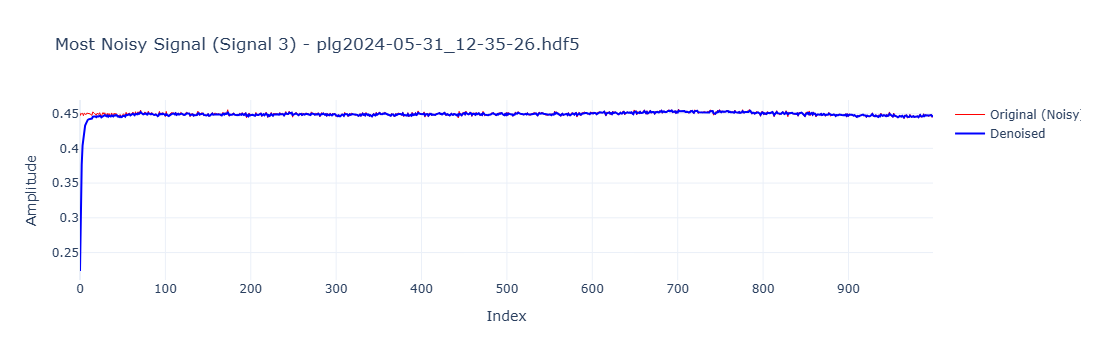

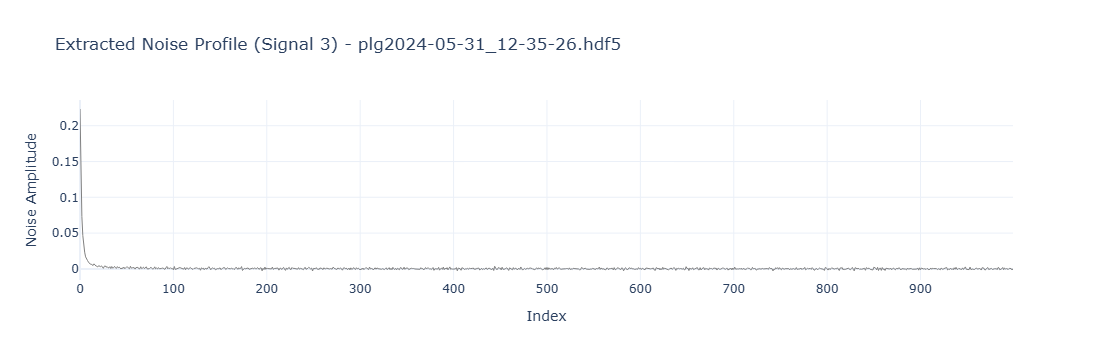

Processing plg2024-05-31_13-35-38.hdf5...


Calculating Noise Energy: 100%|████████████████████████████████████| 72002560/72002560 [00:05<00:00, 12787840.69rows/s]


==================== REPORT: plg2024-05-31_13-35-38.hdf5 ====================

[Data Inspection] First 10 rows:
   Original 1  Original 2  Original 3  Original 4  Denoised 1  Denoised 2  \
0    0.711323    1.095517    0.445507    1.139392    0.677502    0.760239   
1    0.715323    1.096329    0.442632    1.140830    0.694994    0.922146   
2    0.714948    1.092579    0.444507    1.140517    0.698925    0.978635   
3    0.709636    1.094579    0.445319    1.143642    0.696113    1.008048   
4    0.718448    1.094767    0.445819    1.142205    0.705856    1.024762   
5    0.714948    1.096704    0.446319    1.141705    0.703700    1.036841   
6    0.713698    1.095267    0.443007    1.143017    0.703272    1.043651   
7    0.713573    1.095642    0.438507    1.140830    0.703758    1.049394   
8    0.714198    1.096767    0.444382    1.140580    0.704863    1.054539   
9    0.716636    1.096329    0.444194    1.142705    0.707631    1.057885   

   Denoised 3  Denoised 4  
0    0.4367

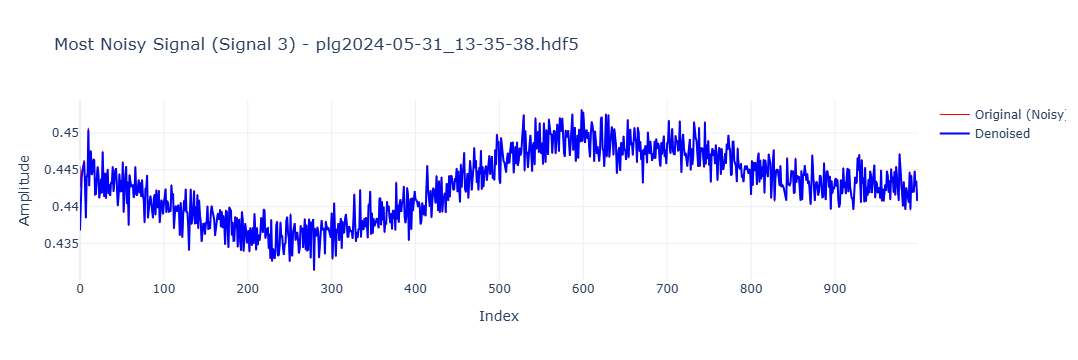

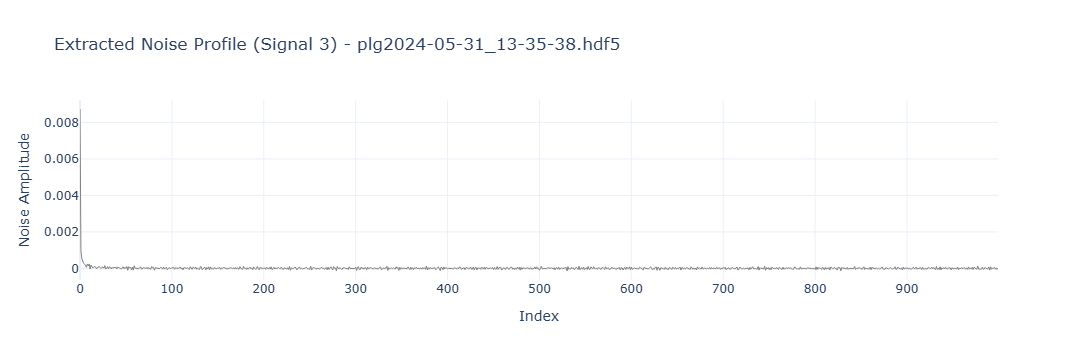

Processing plg2024-05-31_14-35-50.hdf5...


Calculating Noise Energy: 100%|████████████████████████████████████| 72002560/72002560 [00:05<00:00, 13041642.15rows/s]


==================== REPORT: plg2024-05-31_14-35-50.hdf5 ====================

[Data Inspection] First 10 rows:
   Original 1  Original 2  Original 3  Original 4  Denoised 1  Denoised 2  \
0    0.775137    1.078079    0.384193    1.145517    0.387568    0.539039   
1    0.772262    1.076891    0.382068    1.144267    0.560537    0.781013   
2    0.774449    1.078516    0.382006    1.145080    0.648186    0.902843   
3    0.773762    1.076141    0.379693    1.145018    0.694374    0.966370   
4    0.774637    1.078391    0.385693    1.146767    0.720674    1.003154   
5    0.775449    1.078329    0.387006    1.145080    0.736468    1.024606   
6    0.770824    1.078954    0.385068    1.143955    0.743790    1.038090   
7    0.773699    1.077454    0.385506    1.144080    0.750366    1.045961   
8    0.775012    1.075266    0.385381    1.142892    0.755302    1.050316   
9    0.775262    1.078016    0.382881    1.146705    0.758685    1.055090   

   Denoised 3  Denoised 4  
0    0.1920

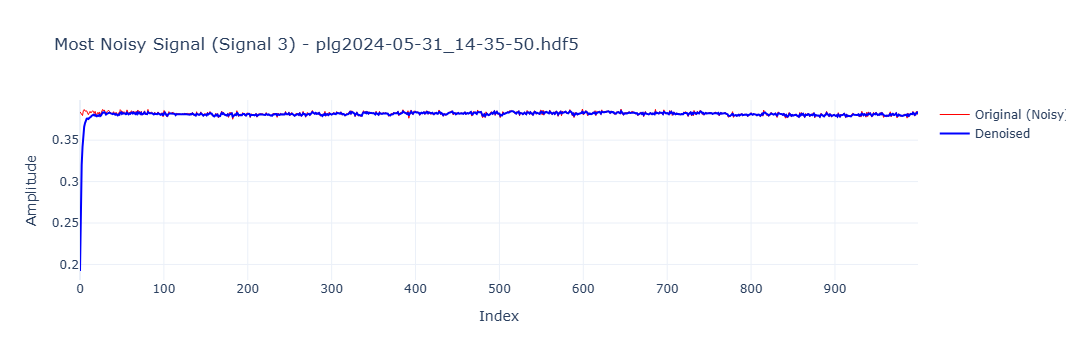

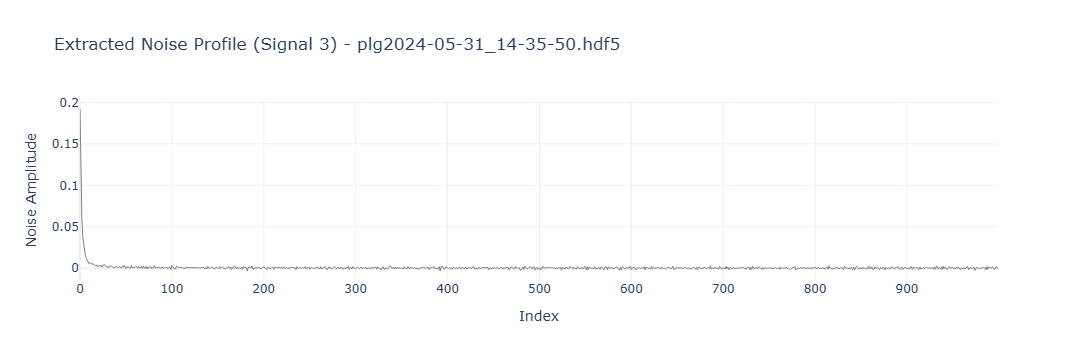

Processing plg2024-05-31_15-36-02.hdf5...


Calculating Noise Energy: 100%|████████████████████████████████████| 18454016/18454016 [00:01<00:00, 13007749.20rows/s]


==================== REPORT: plg2024-05-31_15-36-02.hdf5 ====================

[Data Inspection] First 10 rows:
   Original 1  Original 2  Original 3  Original 4  Denoised 1  Denoised 2  \
0    0.863576    1.048954    0.284192    1.148643    0.431788    0.524477   
1    0.866576    1.046829    0.282567    1.147955    0.627592    0.759429   
2    0.864951    1.046766    0.282379    1.146955    0.724607    0.876927   
3    0.867138    1.045578    0.278129    1.148830    0.777325    0.938820   
4    0.862951    1.048641    0.279567    1.147080    0.804623    0.975057   
5    0.864263    1.049141    0.285004    1.148018    0.821558    0.996402   
6    0.861763    1.048141    0.284629    1.146142    0.830716    1.008935   
7    0.870701    1.047516    0.282067    1.147080    0.841337    1.016758   
8    0.864013    1.048391    0.281504    1.147017    0.844259    1.022561   
9    0.865763    1.044578    0.284067    1.148205    0.847683    1.024668   

   Denoised 3  Denoised 4  
0    0.1420

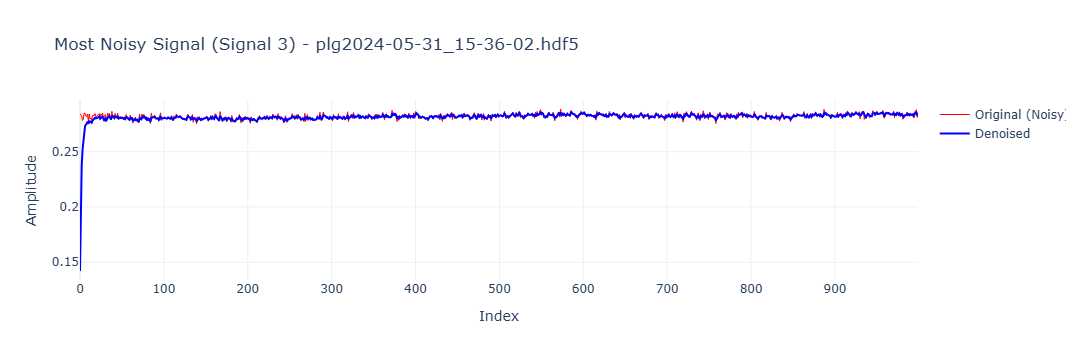

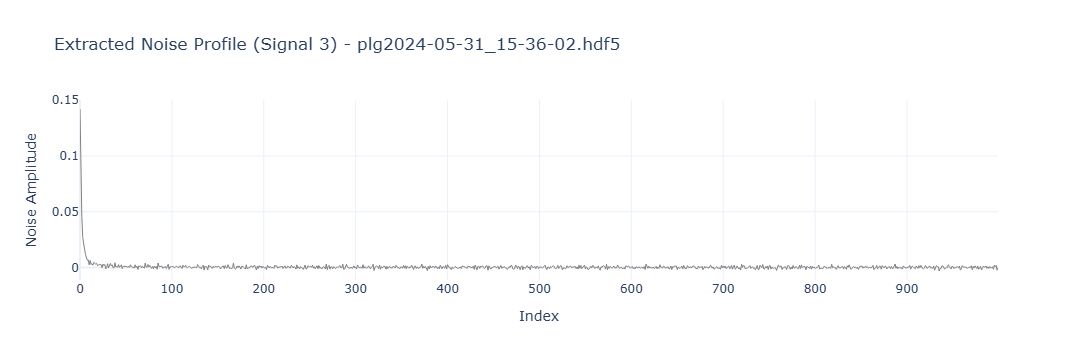

In [ ]:
from pathlib import Path
hdf5_files = sorted(str(p) for p in Path("data").glob("*.hdf5"))

for file_path in hdf5_files:
    if os.path.exists(file_path):
        try:
            energies, sample, _ = calculate_noise_energies(file_path)
            report_and_visualize(file_path, energies, sample)
        except Exception as e:
            print(f"Error processing {file_path}: {e}")
    else:
        print(f"File not found: {file_path}")

## Interactive Visualization

Use the variables below to select the range of data you want to visualize.
This avoids loading the entire dataset into memory for plotting.

In [ ]:
# --- VISUALIZATION SETTINGS ---
VIS_START = 0       # Start index
VIS_END = 5000      # End index (e.g., first 5000 points)
# ------------------------------

Generating plots for plg2024-05-31_12-35-26.hdf5 (Range: 0-5000)...


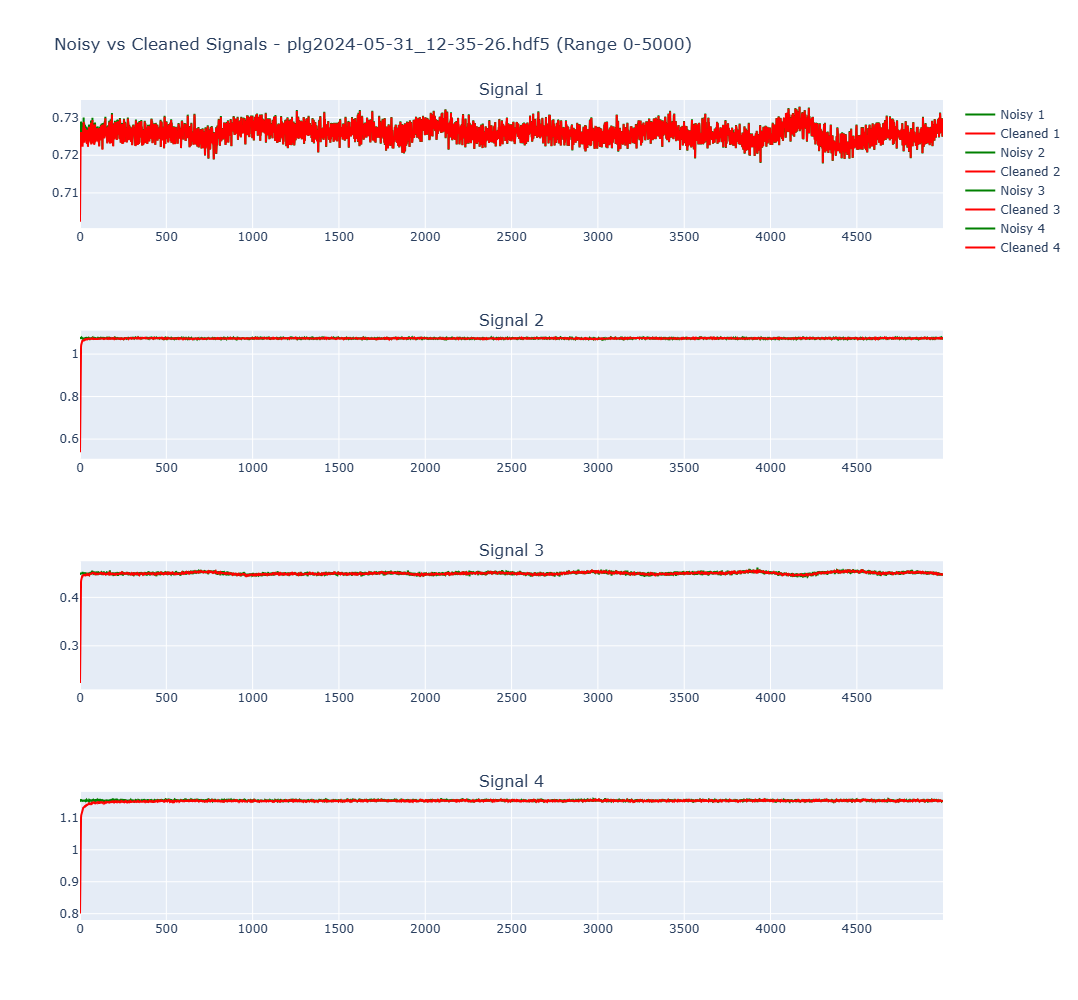

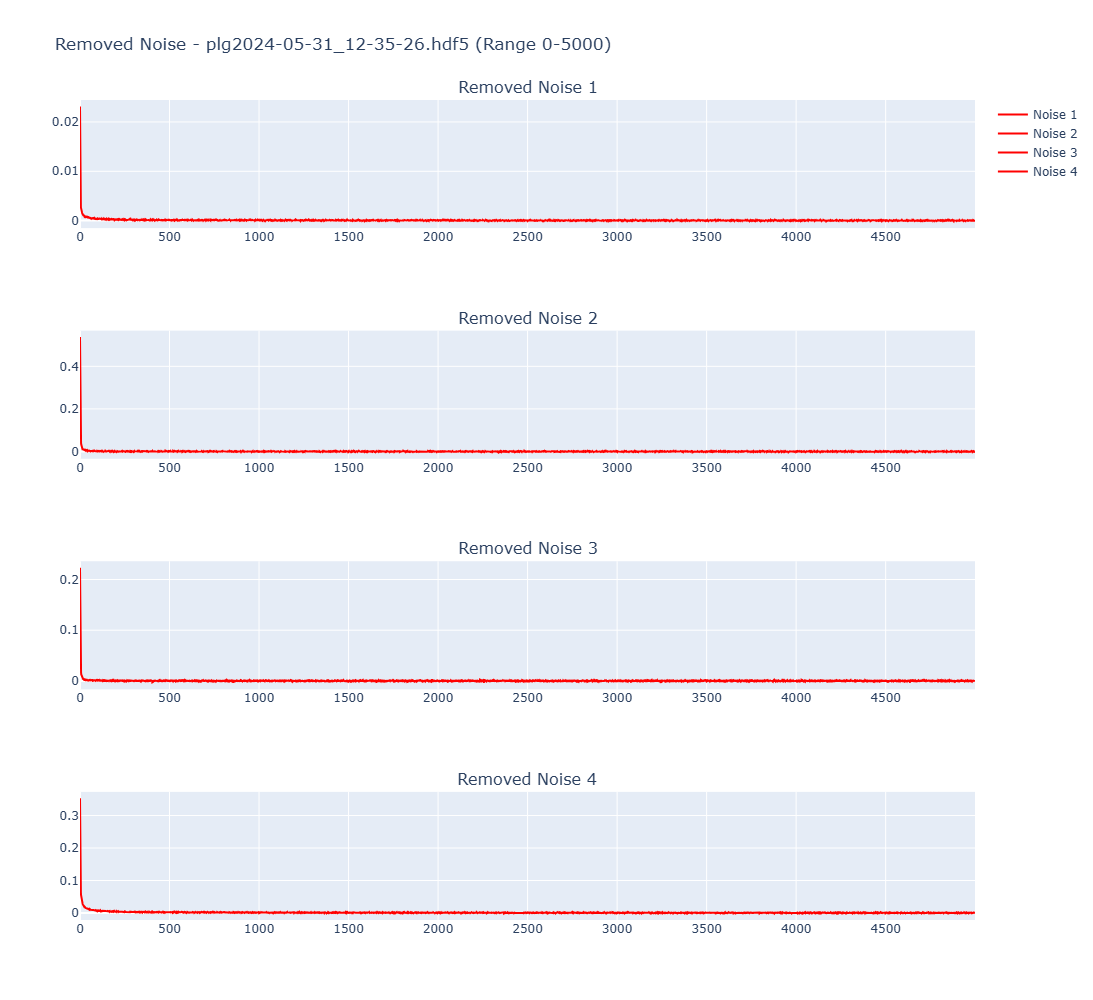

Generating plots for plg2024-05-31_13-35-38.hdf5 (Range: 0-5000)...


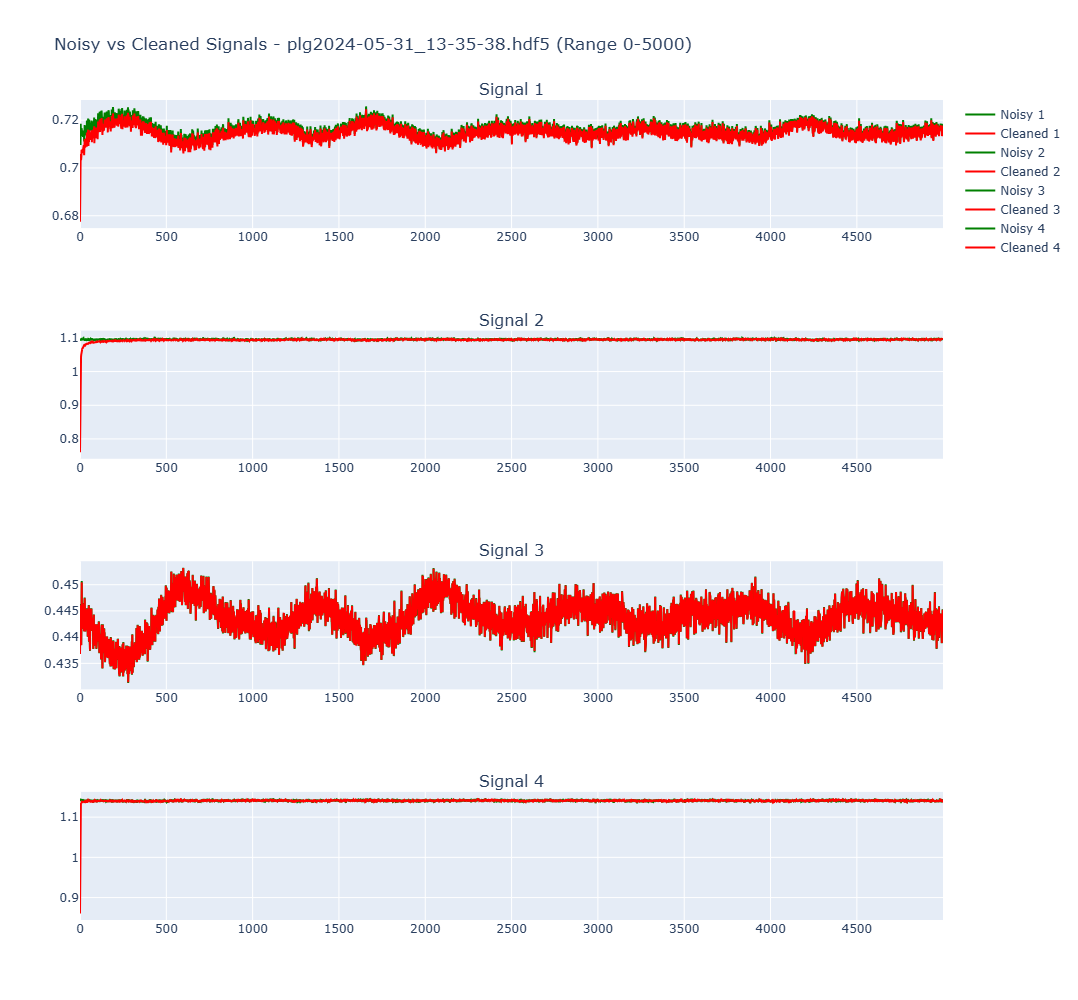

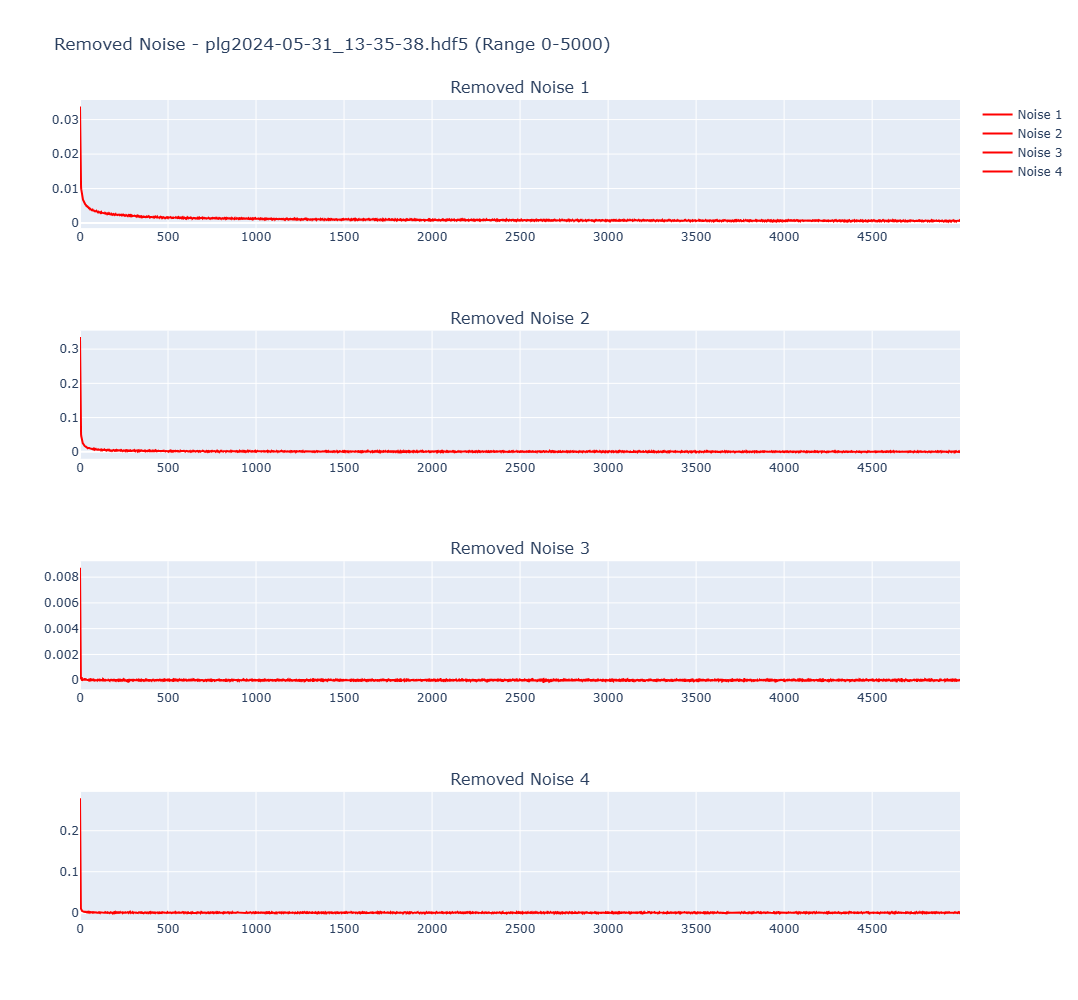

Generating plots for plg2024-05-31_14-35-50.hdf5 (Range: 0-5000)...


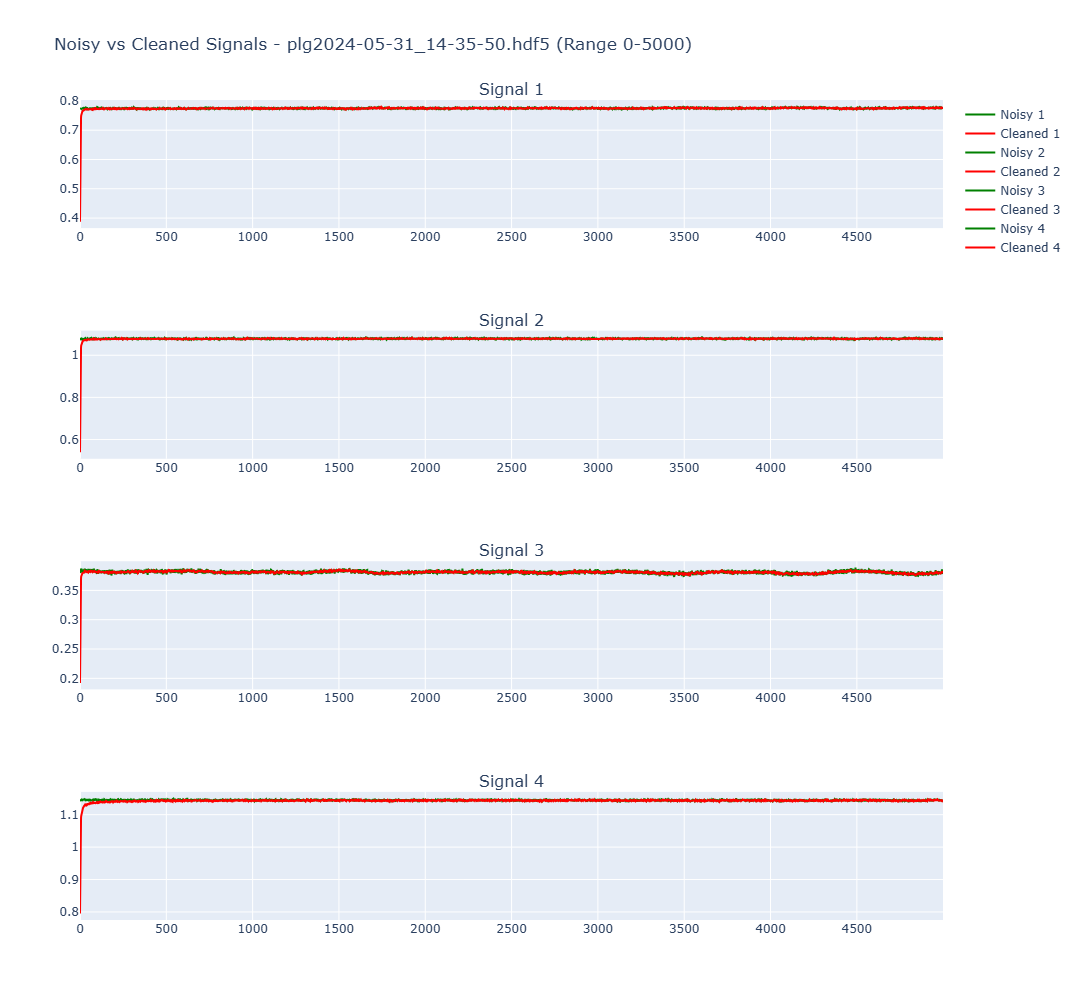

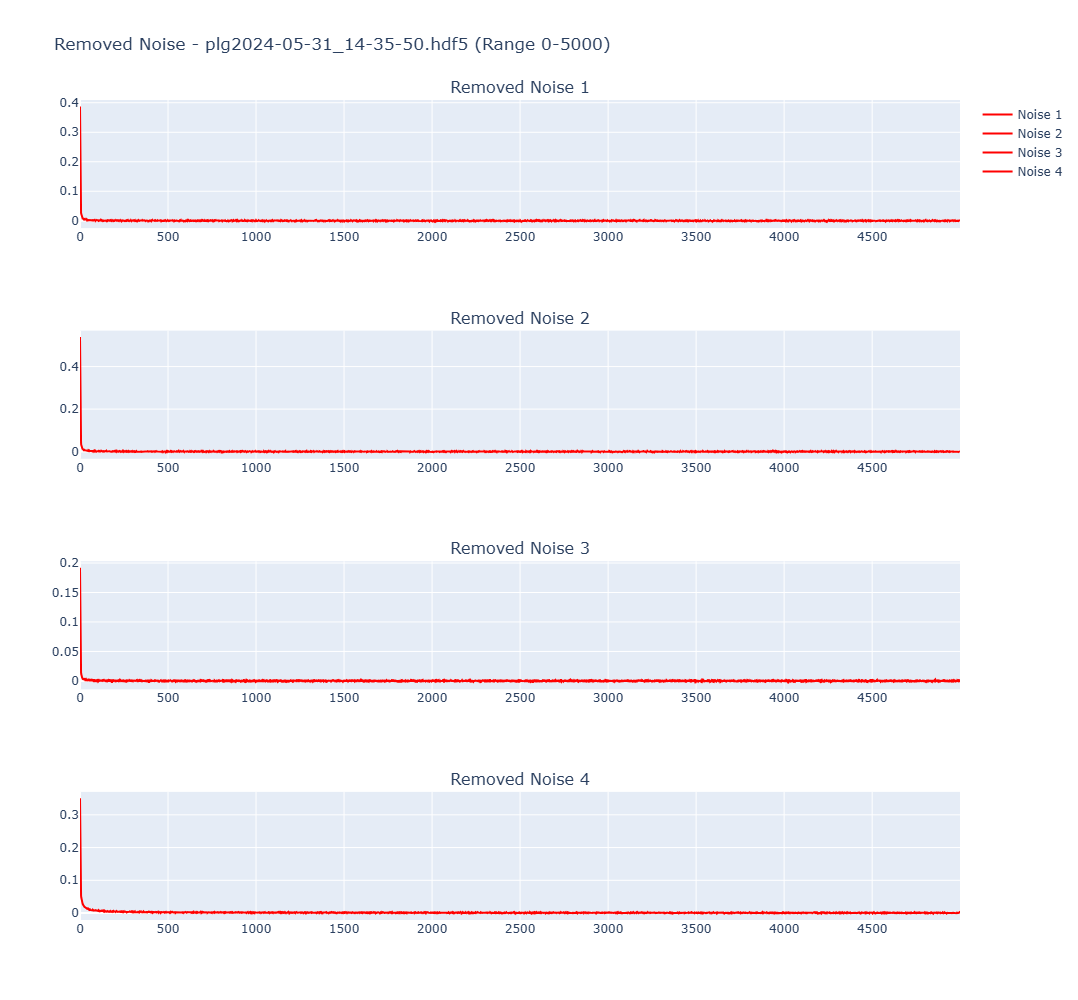

Generating plots for plg2024-05-31_15-36-02.hdf5 (Range: 0-5000)...


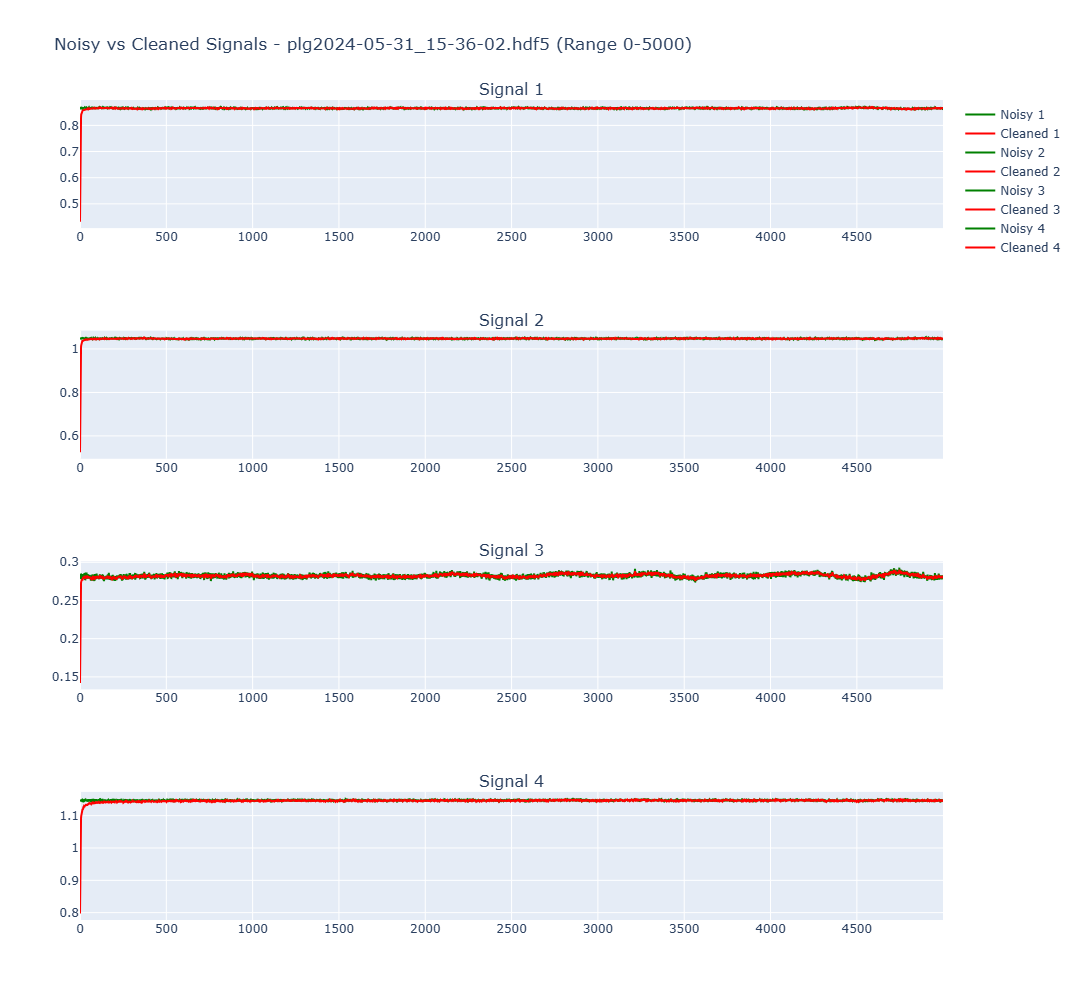

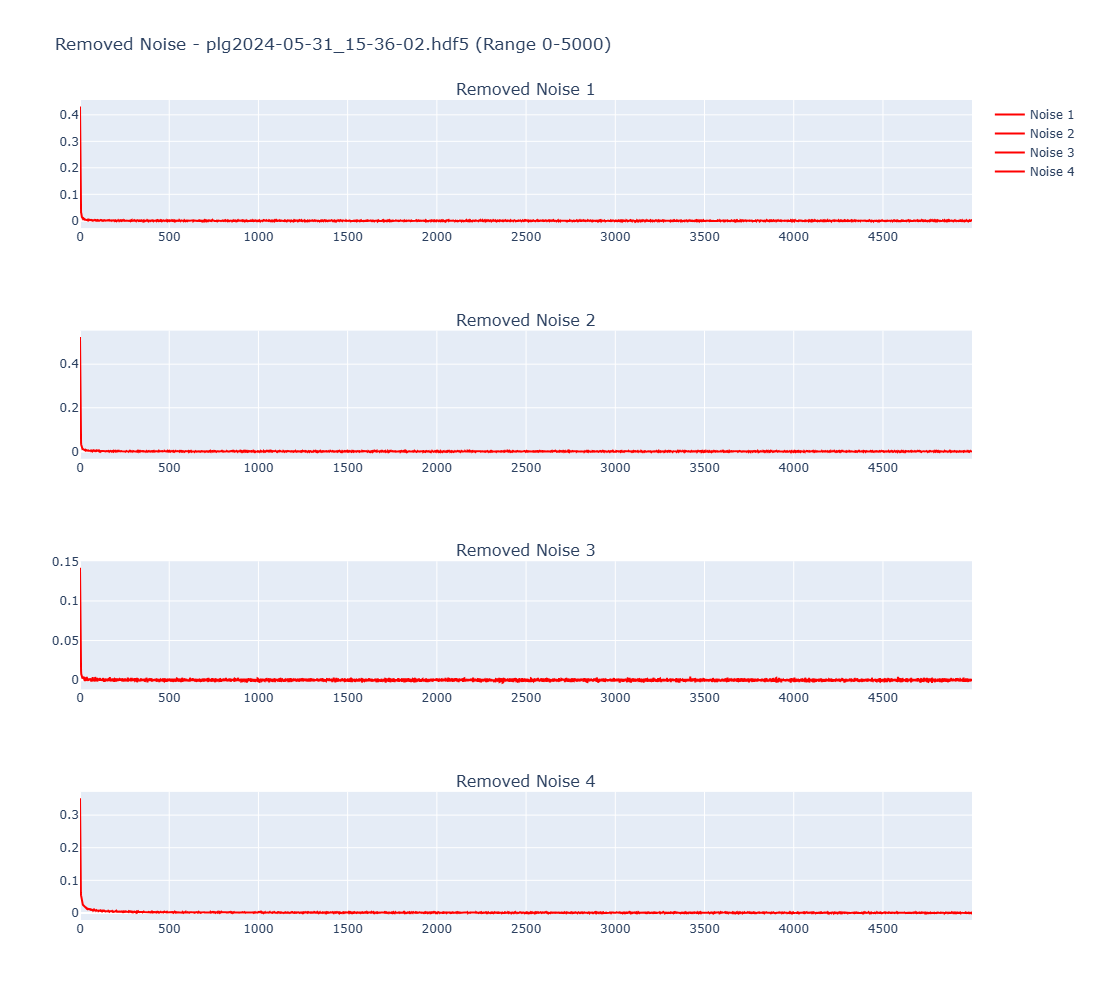

In [ ]:
from pathlib import Path
# Ensure dependencies are loaded for this section
import h5py
import os
import plotly.graph_objects as go
from plotly.subplots import make_subplots

files = sorted(str(p) for p in Path("data").glob("*.hdf5"))

for file_name in files:
    if not os.path.exists(file_name):
        continue

    print(f"Generating plots for {file_name} (Range: {VIS_START}-{VIS_END})...")

    with h5py.File(file_name, "r") as f:
        if "combined_data" not in f:
            print("combined_data not found. Run processing first.")
            continue

        dset = f["combined_data"]

        # Validate range
        max_len = dset.shape[0]
        start = max(0, VIS_START)
        end = min(max_len, VIS_END)

        if start >= end:
            print("Invalid range selected.")
            continue

        # Load specific range
        data_sample = dset[start:end, :]

        # Plot 1: Signals (Noisy vs Cleaned)
        fig_signals = make_subplots(rows=4, cols=1, subplot_titles=[f"Signal {i+1}" for i in range(4)])

        for i in range(4):
            noisy = data_sample[:, i]
            clean = data_sample[:, 4+i]

            fig_signals.add_trace(go.Scatter(y=noisy, mode='lines', name=f'Noisy {i+1}', line=dict(color='green')), row=i+1, col=1)
            fig_signals.add_trace(go.Scatter(y=clean, mode='lines', name=f'Cleaned {i+1}', line=dict(color='red')), row=i+1, col=1)

        fig_signals.update_layout(height=1000, title_text=f"Noisy vs Cleaned Signals - {file_name} (Range {start}-{end})")
        fig_signals.show()

        # Plot 2: Removed Noise
        fig_noise = make_subplots(rows=4, cols=1, subplot_titles=[f"Removed Noise {i+1}" for i in range(4)])

        for i in range(4):
            noisy = data_sample[:, i]
            clean = data_sample[:, 4+i]
            noise = noisy - clean

            fig_noise.add_trace(go.Scatter(y=noise, mode='lines', name=f'Noise {i+1}', line=dict(color='red')), row=i+1, col=1)

        fig_noise.update_layout(height=1000, title_text=f"Removed Noise - {file_name} (Range {start}-{end})")
        fig_noise.show()

## Optional: destructive dataset compaction

**Use only on a copy of your data.** The next cell replaces the selected HDF5 dataset with a version containing only columns after the first four. This is irreversible unless you have a backup. It is not required for denoising or noise analysis.


In [ ]:
from pathlib import Path
# Efficiently delete the first 4 columns of each HDF5 file
import h5py
import numpy as np
import os

files = sorted(str(p) for p in Path("data").glob("*.hdf5"))

def delete_first_4_columns(file_path, chunk_size=1000000):
    if not os.path.exists(file_path):
        print(f"File not found: {file_path}")
        return

    print(f"Processing {file_path}...")

    with h5py.File(file_path, 'r+') as f:
        # Identify the dataset
        if 'combined_data' in f:
            dset_name = 'combined_data'
        elif 'arr' in f:
            dset_name = 'arr'
        else:
            print(f"  No suitable dataset found in {file_path}")
            return

        dset = f[dset_name]
        shape = dset.shape
        dtype = dset.dtype

        # Check if we have enough columns
        if shape[1] <= 4:
            print(f"  Dataset has {shape[1]} columns. Cannot delete first 4.")
            return

        new_shape = (shape[0], shape[1] - 4)
        print(f"  Reshaping from {shape} to {new_shape}")

        # Create a temporary dataset
        temp_dset_name = dset_name + '_temp'
        if temp_dset_name in f:
            del f[temp_dset_name]

        temp_dset = f.create_dataset(temp_dset_name, shape=new_shape, dtype=dtype)

        # Copy data chunk by chunk
        total_rows = shape[0]
        for i in range(0, total_rows, chunk_size):
            end = min(i + chunk_size, total_rows)
            # Read chunk, keep columns from index 4 onwards
            chunk = dset[i:end, 4:]
            temp_dset[i:end, :] = chunk

            if i % (chunk_size * 10) == 0:
                print(f"  Copied {i}/{total_rows} rows...")

        print("  Copy complete. Swapping datasets...")

        # Delete original and rename temp
        del f[dset_name]
        f.move(temp_dset_name, dset_name)
        print("  Done.")

for file_name in files:
    delete_first_4_columns(file_name)


Processing plg2024-05-31_12-35-26.hdf5...
  Reshaping from (72002560, 8) to (72002560, 4)
  Copied 0/72002560 rows...
  Copied 10000000/72002560 rows...
  Copied 20000000/72002560 rows...
  Copied 30000000/72002560 rows...
  Copied 40000000/72002560 rows...
  Copied 50000000/72002560 rows...
  Copied 60000000/72002560 rows...
  Copied 70000000/72002560 rows...
  Copy complete. Swapping datasets...
  Done.
Processing plg2024-05-31_13-35-38.hdf5...
  Reshaping from (72002560, 8) to (72002560, 4)
  Copied 0/72002560 rows...
  Copied 10000000/72002560 rows...
  Copied 20000000/72002560 rows...
  Copied 30000000/72002560 rows...
  Copied 40000000/72002560 rows...
  Copied 50000000/72002560 rows...
  Copied 60000000/72002560 rows...
  Copied 70000000/72002560 rows...
  Copy complete. Swapping datasets...
  Done.
Processing plg2024-05-31_14-35-50.hdf5...
  Reshaping from (72002560, 8) to (72002560, 4)
  Copied 0/72002560 rows...
  Copied 10000000/72002560 rows...
  Copied 20000000/72002560 ro

In [ ]:
from pathlib import Path
# Read and print the first 10 rows of each dataset
import h5py, os
import pandas as pd

files = sorted(str(p) for p in Path("data").glob("*.hdf5"))

for file_name in files:
    if not os.path.exists(file_name):
        print(f"File not found: {file_name}")
        continue

    print(f"\n{'='*40}")
    print(f"File: {file_name}")
    print(f"{'='*40}")

    with h5py.File(file_name, 'r') as f:
        if 'combined_data' in f:
            dset = f['combined_data']
            dset_name = 'combined_data'
        elif 'arr' in f:
            dset = f['arr']
            dset_name = 'arr'
        else:
            print("No suitable dataset found.")
            continue

        print(f"Dataset: {dset_name}, Shape: {dset.shape}")

        # Read first 10 rows
        data = dset[:10]

        # Create DataFrame for nice display
        df = pd.DataFrame(data)
        print(df)


File not found: plg2024-05-31_12-35-26.hdf5
File not found: plg2024-05-31_13-35-38.hdf5
File not found: plg2024-05-31_14-35-50.hdf5
File not found: plg2024-05-31_15-36-02.hdf5
